# Food Delivery Time Prediction: End-to-End KDD Project
**Aaditi Gaikwad | PRN 23070521052**  
**Predictive Analytics | Submitted to Dr. Deepak Asudani**

## 1. Introduction and problem identification
Estimate total delivery duration in minutes from distance, weather, traffic, time of day, vehicle and courier experience. This is **supervised regression**. The intended use is an initial delivery estimate that supports customer communication and planning.

**Prediction boundary:** `Order_ID` is an identifier and is excluded. `Preparation_Time_min` is recorded preparation duration; the source does not establish that it was an estimate available when ordering. It is excluded from all candidate models to avoid relying on future information. Contextual weather/traffic are treated as supplied conditions; their availability and forecast accuracy would need verification in a live system.

**Success criterion fixed before fitting:** choose the candidate with lowest mean five-fold cross-validation MAE on the development set. Evaluate once on a separate 20% holdout; compare with a training-median baseline. Do not use the holdout to select hyperparameters.

## 2. Data source and literature context
Dataset: Den_Kuznetz (`denkuznetz`), [Food Delivery Time Prediction](https://www.kaggle.com/datasets/denkuznetz/food-delivery-time-prediction), Kaggle, version 1. Kaggle metadata lists **Apache 2.0**; attribution and a metadata snapshot are included. The provider describes columns but does not document a collection period, geography or sampling protocol. It is an educational benchmark, not verified operational data from a named delivery company.

Garg et al. (2025), [arXiv:2503.15177](https://arxiv.org/abs/2503.15177), compare linear and ensemble models in an Indian-delivery setting. Wen et al. (2023), [arXiv:2309.01194](https://arxiv.org/abs/2309.01194), survey route and time prediction. Their abstracts motivate contextual inputs and model comparison; this project uses a different dataset and does not copy their results.

## 3. Reproducibility and setup
Use Python 3.12, install `requirements.txt`, then run from this folder. All input data are local. Random seed 42 fixes the split and model seeds. Core versions and the input checksum are recorded below. Small floating-point differences across platforms are possible.

In [1]:
import os
os.environ['OMP_NUM_THREADS']='2'
from pathlib import Path
import json, hashlib, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, KFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits
import joblib

ROOT=Path.cwd()
assert (ROOT/'data/Food_Delivery_Times.csv').exists(), 'Run from the project folder.'
RESULTS=ROOT/'results';RESULTS.mkdir(exist_ok=True)
(ROOT/'models').mkdir(exist_ok=True)
SEED=42
plt.style.use('seaborn-v0_8-whitegrid')
versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','matplotlib','joblib','nbformat','nbclient','ipykernel','threadpoolctl']}
print('Python:',platform.python_version());display(pd.Series(versions,name='Version').to_frame())

Python: 3.12.14


,Version
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2
joblib,1.6.0
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0
threadpoolctl,3.7.0


## 4. Data understanding and quality audit
One row is one order. `Delivery_Time_min` is the target. Missing predictor values are retained and imputed **inside each training fold**. No target values are filled. The audit checks missingness, duplicate order IDs, duplicated modelling records, and invalid numeric ranges. Large but valid durations are not removed merely to improve a score.

The source includes neither event timestamps nor restaurant/courier identifiers. Random order-level evaluation assumes independent, similarly distributed orders; time-based or entity-based generalization cannot be measured from these columns.

In [2]:
path=ROOT/'data/Food_Delivery_Times.csv'
df=pd.read_csv(path)
cat_cols=['Weather','Traffic_Level','Time_of_Day','Vehicle_Type']
num_cols=['Distance_km','Courier_Experience_yrs']
features=num_cols+cat_cols
target='Delivery_Time_min'
audit={'rows':len(df),'columns':len(df.columns),'missing_cells':int(df.isna().sum().sum()),
       'duplicate_ids':int(df.Order_ID.duplicated().sum()),
       'duplicate_model_records':int(df.duplicated(subset=features+[target]).sum()),
       'sha256':hashlib.sha256(path.read_bytes()).hexdigest()}
assert df[target].notna().all() and (df[target]>0).all()
assert (df.Distance_km>=0).all()
assert (df.Courier_Experience_yrs.dropna()>=0).all()
assert audit['duplicate_ids']==0 and audit['duplicate_model_records']==0
assert not set(features)&{'Order_ID','Preparation_Time_min',target}
display(pd.Series(audit,name='Audit').to_frame())
missing=df.isna().sum().rename('Missing').to_frame()
display(missing);display(df.head())
missing.to_csv(RESULTS/'missing_values.csv')

,Audit
rows,1000
columns,9
missing_cells,120
duplicate_ids,0
duplicate_model_records,0
sha256,9fc2f147a79ee7edec9cc19e70c35d460df713f942b4f1...


,Missing
Order_ID,0
Distance_km,0
Weather,30
Traffic_Level,30
Time_of_Day,30
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,30
Delivery_Time_min,0


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


## 5. Holdout split and development-only exploration
Reserve 20% of rows before exploration. The remaining 80% are used for all model selection. Save the order IDs for an auditable split. The following charts use development data only. The random split is appropriate for the stated independent-order benchmark, but is not evidence of future-period performance.

Development rows: 800 | Final test rows: 200


,Delivery_Time_min,Distance_km,Courier_Experience_yrs
count,800.00,800.00,776.00
mean,57.05,10.10,4.61
std,22.28,5.73,2.95
min,8.00,0.59,0.00
25%,41.00,5.13,2.00
50%,56.00,10.22,5.00
75%,71.00,14.94,7.00
max,153.00,19.99,9.00


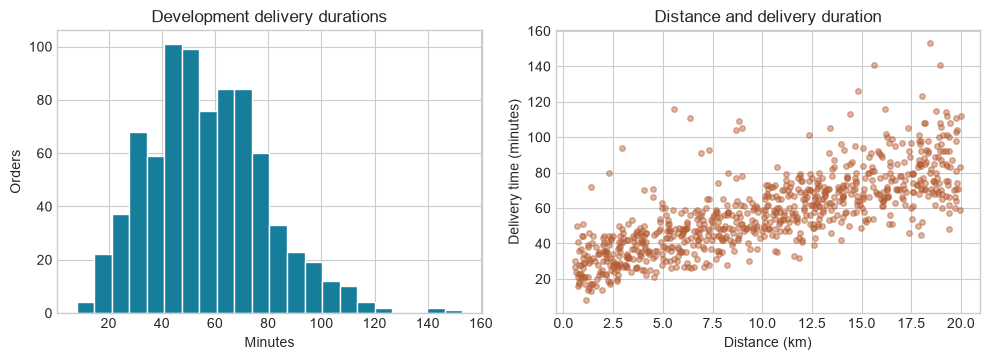

,count,mean,median
Traffic_Level,,,
High,159,64.26,63.0
Low,311,53.32,52.0
Medium,311,56.61,54.0
NaN,19,65.05,58.0


In [3]:
dev_idx,test_idx=train_test_split(np.arange(len(df)),test_size=0.2,random_state=SEED)
dev=df.iloc[dev_idx].copy();test=df.iloc[test_idx].copy()
X_dev,y_dev=dev[features],dev[target]
X_test,y_test=test[features],test[target]
assert set(dev.Order_ID).isdisjoint(set(test.Order_ID))
assert len(dev)+len(test)==len(df)
pd.concat([dev[['Order_ID']].assign(partition='development'),test[['Order_ID']].assign(partition='test')]).to_csv(RESULTS/'split_order_ids.csv',index=False)
print('Development rows:',len(dev),'| Final test rows:',len(test))
display(dev[[target]+num_cols].describe().round(2))
fig,axs=plt.subplots(1,2,figsize=(10,3.7))
axs[0].hist(y_dev,bins=22,color='#167d9a',edgecolor='white')
axs[0].set(title='Development delivery durations',xlabel='Minutes',ylabel='Orders')
axs[1].scatter(dev.Distance_km,y_dev,s=16,alpha=.45,color='#b45c32')
axs[1].set(title='Distance and delivery duration',xlabel='Distance (km)',ylabel='Delivery time (minutes)')
fig.tight_layout();fig.savefig(RESULTS/'eda.png',dpi=180,bbox_inches='tight');plt.show()
display(dev.groupby('Traffic_Level',dropna=False)[target].agg(['count','mean','median']).round(2))

**Interpretation:** distance can explain part of the variation, but two orders at similar distances can still have different durations. Traffic comparisons are descriptive associations, not randomized causal estimates. Missing categories are not discarded. A record with a long delivery time could represent a valid difficult order.

## 6. Preprocessing and candidate models
Numerical features use median imputation with missingness indicators followed by scaling. Categorical features use a distinct `Unknown` value for missing entries and one-hot encoding. Unknown categories at prediction time are ignored by the encoder; inputs outside the known schema should normally be reviewed instead of trusted blindly.

The seven predeclared candidates are a median baseline, two Ridge settings, two random-forest settings and two histogram-boosting settings. Ridge supplies an additive linear comparison. Tree ensembles capture nonlinearities and interactions. Every fold fits its own preprocessing. Clipping to zero is applied in validation and final inference; no rounding is used in evaluation.

In [4]:
def build(model):
    numeric=Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),('scale',StandardScaler())])
    category=Pipeline([('impute',SimpleImputer(strategy='constant',fill_value='Unknown')),
                       ('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
    prep=ColumnTransformer([('numeric',numeric,num_cols),('categorical',category,cat_cols)])
    return Pipeline([('prepare',prep),('model',model)])
candidates={
    'Median baseline':DummyRegressor(strategy='median'),
    'Ridge alpha=1':Ridge(alpha=1),
    'Ridge alpha=10':Ridge(alpha=10),
    'Random forest leaf=2':RandomForestRegressor(n_estimators=200,min_samples_leaf=2,random_state=SEED,n_jobs=2),
    'Random forest leaf=5':RandomForestRegressor(n_estimators=200,min_samples_leaf=5,random_state=SEED,n_jobs=2),
    'Boosting leaves=7':HistGradientBoostingRegressor(max_iter=200,max_leaf_nodes=7,learning_rate=.05,early_stopping=False,random_state=SEED),
    'Boosting leaves=15':HistGradientBoostingRegressor(max_iter=200,max_leaf_nodes=15,learning_rate=.05,early_stopping=False,random_state=SEED)
}
folds=list(KFold(n_splits=5,shuffle=True,random_state=SEED).split(X_dev))
records=[]
with threadpool_limits(limits=2):
    for name,model in candidates.items():
        for fold,(tr,va) in enumerate(folds,1):
            assert set(tr).isdisjoint(set(va))
            fit=build(clone(model)).fit(X_dev.iloc[tr],y_dev.iloc[tr])
            pred=np.maximum(0,fit.predict(X_dev.iloc[va]))
            records.append({'model':name,'fold':fold,'MAE':mean_absolute_error(y_dev.iloc[va],pred)})
        print('Completed:',name)
cv_raw=pd.DataFrame(records)
cv_table=cv_raw.groupby('model').MAE.agg(['mean','std']).sort_values('mean')
cv_table.columns=['CV_MAE','CV_SD'];best_name=cv_table.index[0]
display(cv_table.round(3));print('Selected only from CV:',best_name)
cv_raw.to_csv(RESULTS/'cv_fold_scores.csv',index=False)
cv_table.to_csv(RESULTS/'cv_comparison.csv')

Completed: Median baseline
Completed: Ridge alpha=1


Completed: Ridge alpha=10


Completed: Random forest leaf=2


Completed: Random forest leaf=5


Completed: Boosting leaves=7


Completed: Boosting leaves=15


,CV_MAE,CV_SD
model,,
Ridge alpha=10,9.376,0.509
Ridge alpha=1,9.397,0.531
Boosting leaves=7,10.082,0.547
Random forest leaf=5,10.086,0.660
Random forest leaf=2,10.207,0.685
Boosting leaves=15,10.490,0.643
Median baseline,17.916,0.600


Selected only from CV: Ridge alpha=10


## 7. Final model and test evaluation
Refit the selected configuration on all 800 development orders, then score the 200 held-out orders once. The baseline median is calculated from development targets, not test targets.

- **MAE:** average absolute error in minutes; primary metric.
- **RMSE:** square root of mean squared error; larger misses receive greater weight.
- **R²:** improvement in squared error over a constant test-mean reference; not “percentage accuracy.”
- **Within 10 minutes:** share of absolute errors at most 10 minutes, a supplementary descriptive tolerance measure fixed before test scoring. It is not a service-level guarantee.

,Model,MAE,RMSE,R2,Within_10_min_percent
0,Median baseline,17.465,21.179,-0.001,31.5
1,Ridge alpha=10,8.568,11.136,0.723,66.5


Training metrics: {'MAE': 9.202819325516058, 'RMSE': 12.783530230676524, 'R2': 0.6703430622079879, 'Within_10_min_percent': 63.0}


,n,MAE
Traffic_Level,,
High,38,11.256
Low,72,8.397
Medium,79,7.759
Unknown,11,6.223


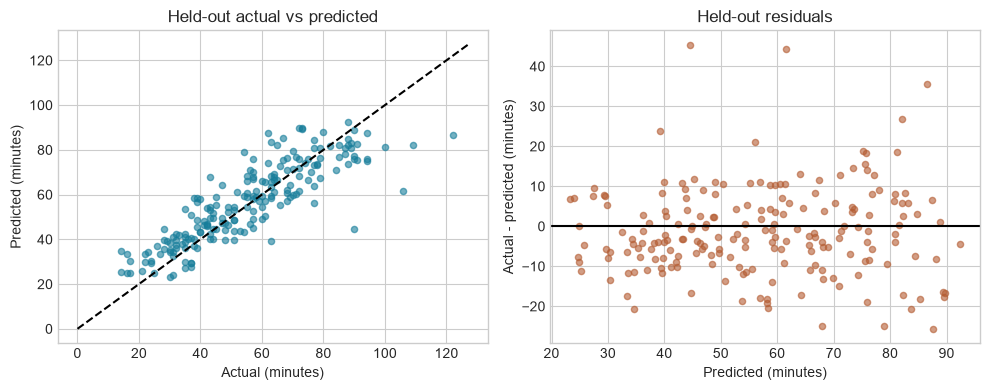

In [5]:
def metrics(y,p):
    return {'MAE':float(mean_absolute_error(y,p)),
            'RMSE':float(np.sqrt(mean_squared_error(y,p))),
            'R2':float(r2_score(y,p)),
            'Within_10_min_percent':float(100*np.mean(np.abs(np.asarray(y)-p)<=10))}
with threadpool_limits(limits=2):
    final_model=build(clone(candidates[best_name])).fit(X_dev,y_dev)
    baseline=build(DummyRegressor(strategy='median')).fit(X_dev,y_dev)
    pred=np.maximum(0,final_model.predict(X_test))
    bp=np.maximum(0,baseline.predict(X_test))
    train_pred=np.maximum(0,final_model.predict(X_dev))
test_metrics=metrics(y_test,pred);baseline_metrics=metrics(y_test,bp);train_metrics=metrics(y_dev,train_pred)
comparison=pd.DataFrame([{'Model':'Median baseline',**baseline_metrics},{'Model':best_name,**test_metrics}])
display(comparison.round(3));print('Training metrics:',train_metrics)
improvement=100*(baseline_metrics['MAE']-test_metrics['MAE'])/baseline_metrics['MAE']
comparison.to_csv(RESULTS/'test_metrics.csv',index=False)
predictions=test[['Order_ID','Traffic_Level',target]].copy()
predictions['prediction']=pred;predictions['residual']=y_test.to_numpy()-pred
predictions['absolute_error']=np.abs(predictions.residual)
predictions.to_csv(RESULTS/'test_predictions.csv',index=False)
traffic=predictions.assign(Traffic_Level=predictions.Traffic_Level.fillna('Unknown')).groupby('Traffic_Level').agg(n=(target,'size'),MAE=('absolute_error','mean'))
display(traffic.round(3));traffic.to_csv(RESULTS/'error_by_traffic.csv')
fig,axs=plt.subplots(1,2,figsize=(10,4))
axs[0].scatter(y_test,pred,alpha=.6,s=20,color='#167d9a')
limits=[0,max(y_test.max(),pred.max())+5];axs[0].plot(limits,limits,'k--')
axs[0].set(title='Held-out actual vs predicted',xlabel='Actual (minutes)',ylabel='Predicted (minutes)')
axs[1].scatter(pred,predictions.residual,alpha=.6,s=20,color='#b45c32');axs[1].axhline(0,color='black')
axs[1].set(title='Held-out residuals',xlabel='Predicted (minutes)',ylabel='Actual - predicted (minutes)')
fig.tight_layout();fig.savefig(RESULTS/'diagnostics.png',dpi=180,bbox_inches='tight');plt.show()

## 8. Interpretation and limitations of importance
The following analysis is performed after freezing the model and is not used to revise it. Permutation importance measures the MAE increase when a raw feature is shuffled. It expresses dependence of this model's predictions on an input, not a causal influence. Correlated variables can share importance; shuffled combinations can be unrealistic. Repeat standard deviations are shuffle variability, not confidence intervals for population effects.

,feature,MAE_increase,repeat_SD
0,Distance_km,12.756,0.652
2,Weather,1.082,0.145
3,Traffic_Level,1.042,0.232
1,Courier_Experience_yrs,0.273,0.117
4,Time_of_Day,-0.007,0.102
5,Vehicle_Type,-0.047,0.024


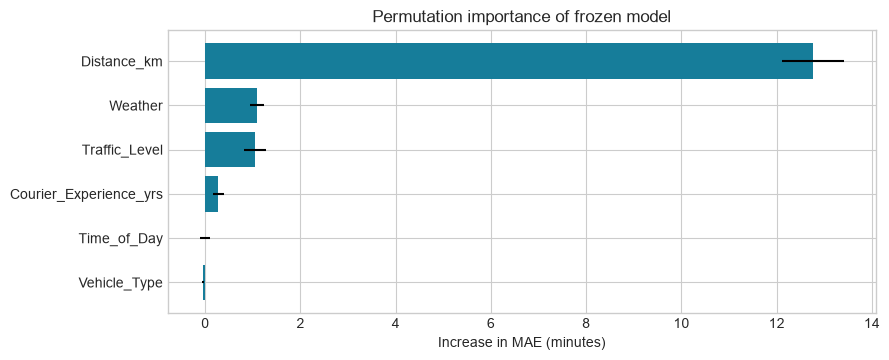

Selected model: **Ridge alpha=10**. Test MAE: **8.57 minutes**; RMSE: **11.14 minutes**; R²: **0.723**. MAE reduction versus the median baseline: **50.9%**. Most influential shuffled input: **Distance_km**.

In [6]:
def clipped_score(estimator,X,y):
    return -mean_absolute_error(y,np.maximum(0,estimator.predict(X)))
with threadpool_limits(limits=2):
    pi=permutation_importance(final_model,X_test,y_test,scoring=clipped_score,n_repeats=10,random_state=SEED,n_jobs=1)
importance=pd.DataFrame({'feature':features,'MAE_increase':pi.importances_mean,'repeat_SD':pi.importances_std}).sort_values('MAE_increase',ascending=False)
display(importance.round(3));importance.to_csv(RESULTS/'permutation_importance.csv',index=False)
fig,ax=plt.subplots(figsize=(9,3.7));v=importance.iloc[::-1]
ax.barh(v.feature,v.MAE_increase,xerr=v.repeat_SD,color='#167d9a')
ax.set(title='Permutation importance of frozen model',xlabel='Increase in MAE (minutes)')
fig.tight_layout();fig.savefig(RESULTS/'importance.png',dpi=180,bbox_inches='tight');plt.show()
display(Markdown(f"Selected model: **{best_name}**. Test MAE: **{test_metrics['MAE']:.2f} minutes**; "
                f"RMSE: **{test_metrics['RMSE']:.2f} minutes**; R²: **{test_metrics['R2']:.3f}**. "
                f"MAE reduction versus the median baseline: **{improvement:.1f}%**. "
                f"Most influential shuffled input: **{importance.iloc[0].feature}**."))

## 9. Export and inference example
Save the entire preprocessing + estimator pipeline. Reload it and check that the example result agrees exactly with the original prediction. The example is the first held-out row, with no target or preparation duration passed to the estimator. `predict.py` provides an independent command-line entry point. Load only trusted joblib artifacts.

The exported model remains fitted on development data; it is not refitted on the test set, which preserves the meaning of the reported holdout result.

In [7]:
model_path=ROOT/'models/food_delivery.joblib'
joblib.dump(final_model,model_path,compress=3)
reloaded=joblib.load(model_path)
sample=X_test.iloc[[0]].copy();sample.to_csv(ROOT/'data/example_input.csv',index=False)
example=np.maximum(0,reloaded.predict(sample))
np.testing.assert_allclose(example,pred[:1],rtol=1e-10)
assert len(pred)==len(test) and np.isfinite(pred).all() and (pred>=0).all()
assert len(cv_raw)==35
display(sample);print(f'Predicted: {example[0]:.2f} minutes; actual: {y_test.iloc[0]} minutes')
summary={'audit':audit,'development_rows':len(dev),'test_rows':len(test),'selected_model':best_name,
         'test_metrics':test_metrics,'baseline_metrics':baseline_metrics,'train_metrics':train_metrics,
         'mae_improvement_percent':improvement,'features':features,'versions':versions,
         'python':platform.python_version(),'example_prediction':float(example[0]),'example_actual':int(y_test.iloc[0])}
(RESULTS/'summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('Checks passed: split separation, excluded predictors, finite outputs and model reload agreement.')

,Distance_km,Courier_Experience_yrs,Weather,Traffic_Level,Time_of_Day,Vehicle_Type
521,5.3,5.0,Clear,Low,Evening,Bike


Predicted: 37.62 minutes; actual: 32 minutes
Checks passed: split separation, excluded predictors, finite outputs and model reload agreement.


## 10. Conclusion and future work
This project demonstrates all KDD stages with an executed model comparison, independent holdout, missing-data handling, error analysis and reusable artifact. Interpret the output metrics above in minutes; do not call R² a classification accuracy.

Limitations: only 1,000 records, incomplete collection provenance, no timestamps or entity IDs, contextual conditions may be observed rather than forecast, no menu/kitchen workload data and no calibrated prediction intervals. Excluding preparation duration protects the input boundary but leaves genuine variation unexplained. Random holdout performance does not establish future-city or future-period reliability.

Future work should collect timestamped operational records with explicitly time-available features, retain known-at-order preparation **estimates** separately from actual preparation duration, evaluate time/entity holdouts and calibrated uncertainty, and monitor errors after deployment. A prediction should support communication rather than pressure couriers into unsafe driving.

## References
1. Den_Kuznetz. Food Delivery Time Prediction. Kaggle, version 1. https://www.kaggle.com/datasets/denkuznetz/food-delivery-time-prediction
2. Garg, A., Ayaan, M., Parekh, S., & Udandarao, V. (2025). Food Delivery Time Prediction in Indian Cities Using Machine Learning Models. arXiv:2503.15177. https://arxiv.org/abs/2503.15177
3. Wen, H., et al. (2023). A Survey on Service Route and Time Prediction in Instant Delivery: Taxonomy, Progress, and Prospects. arXiv:2309.01194. https://arxiv.org/abs/2309.01194
4. scikit-learn. Pipelines and composite estimators. https://scikit-learn.org/stable/modules/compose.html
5. scikit-learn. Cross-validation. https://scikit-learn.org/stable/modules/cross_validation.html
6. scikit-learn. Permutation importance. https://scikit-learn.org/stable/modules/permutation_importance.html

Accessed 11 October 2026. The research summaries use public abstracts; no claim of replicating the cited papers is made.